# Trying to simulate the behavior of an exp2 module tied to the DDS 
 I have never tried to work on this before, so just trying to minimize use of multiplies. Used AI to help me learn about fixed point arithmetic and how best to turn the fractional bit into a LUT
 The overall approach is 3 steps
 1. 2^(Xi + Xf) = 2^(Xi)*2^(Xf)
 2. Turn the 2^Xi operation into a shift
 3. Create a lookup table so that we can precalculate 2^Xf 

 The reason why we need an exp2 function is that while our DDS is able to access every frequency desired by us, it operates in a linear fashion. Notes (and the human ear) operate in a exponential fashion. A4 (440Hz) is one octave below A5 (880Hz), every octave is a doubling of frequency, so cranking the encoder nob at high frequencies becomes an insane ask when operating within higher frequency ranges

157482


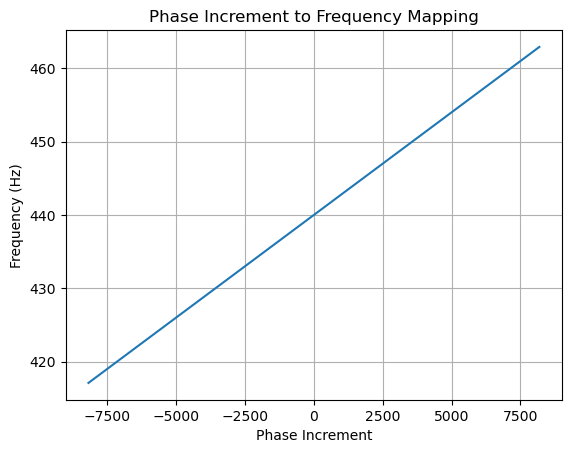

In [127]:
# Beginning of my code
# Attempting an approach that is more intelligible to me, 
# using just fixed point math, plus exponential mapping 
# 
# trying out an exponential mapping for pitch to phase increment
BIT_WIDTH = 14
FRAC_BITS = 10
INT_BITS = BIT_WIDTH - FRAC_BITS - 1

PHASE_W = 24
SAMPLE_RATE = 46875

BASE_FREQ = 440   # A4 frequency in Hz
BASE_PHASE_INC = round(BASE_FREQ * 2**PHASE_W / SAMPLE_RATE)   # phase_inc at pitch 0 (A4)
print(BASE_PHASE_INC)

def phase_inc_to_freq(phase_inc):
    return phase_inc * SAMPLE_RATE / 2**PHASE_W

input_range = np.arange(-2**(BIT_WIDTH-1), 2**(BIT_WIDTH-1))

# this is what mapping looks like if we don't do any exponential mapping and just add the base phase increment
output_freqs = phase_inc_to_freq(input_range + BASE_PHASE_INC)
plt.plot(input_range, output_freqs)
plt.xlabel("Phase Increment")
plt.ylabel("Frequency (Hz)")
plt.title("Phase Increment to Frequency Mapping")
plt.grid(True)
plt.show()


[0.70854417 0.70902394 0.70950404 ... 1.41134463 1.41230029 1.4132566 ]
['0x16ac' '0x16b0' '0x16b4' ... '0x2d29' '0x2d31' '0x2d39']
size of frac_lut: 1024
values stored in LUT as decimal: [0.70849609 0.70898438 0.70947266 ... 1.41125488 1.41223145 1.41320801]


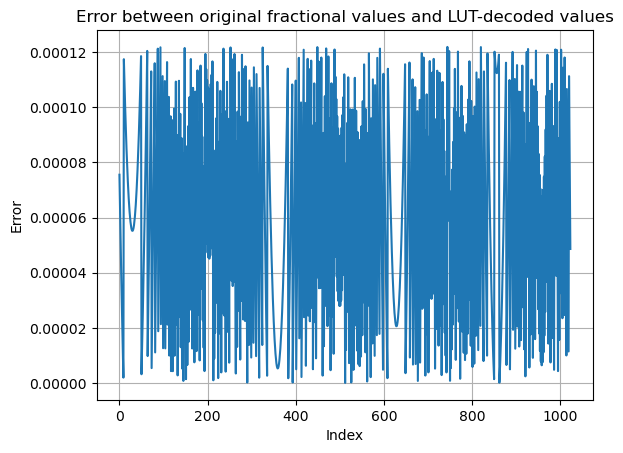

In [118]:
# exponential mapping for pitch to phase increment
# first create LUT for fractional component to map to 2^(-0.5, 0.5) range of input values
frac_values = np.zeros(2**FRAC_BITS)
mid_index = 2**(FRAC_BITS-1)
for i in range(2**FRAC_BITS):
    frac_values[i] = 2 ** ((i - 2**(FRAC_BITS-1)) / 2**FRAC_BITS)
print(frac_values[3:])
# make this LUT all 16 bit values, but only with 2^10 addresses
# this means 1 bit for the integer part and 15 bits for the fractional part
frac_lut_hex = np.zeros(2**(FRAC_BITS), dtype=object)
frac_lut_val = np.zeros(2**(FRAC_BITS), dtype=int)
for i in range(2**(FRAC_BITS)):
    frac_lut_val[i] = int(frac_values[i] * (2**(BIT_WIDTH-1)))
    frac_lut_hex[i] = hex(frac_lut_val[i])
print(frac_lut_hex[3:])
print("size of frac_lut:", frac_lut_hex.size)

#convert back to decimal values
frac_lut_dec = np.zeros(2**FRAC_BITS)
for i in range(2**FRAC_BITS):
    frac_lut_dec[i] = int(frac_lut_hex[i], 16) / (2**(BIT_WIDTH-1))
print("values stored in LUT as decimal:", frac_lut_dec[3:])

# plot error between original fractional values and LUT-decoded values
plt.plot(frac_values - frac_lut_dec)
plt.xlabel("Index")
plt.ylabel("Error")
plt.title("Error between original fractional values and LUT-decoded values")
plt.grid(True)
plt.show()

Beginning of input range: [-8192 -8191 -8190] Hex:  ['0x2000' '0x2001' '0x2002']
End of input range: [8189 8190 8191] Hex:  ['0x1ffd' '0x1ffe' '0x1fff']


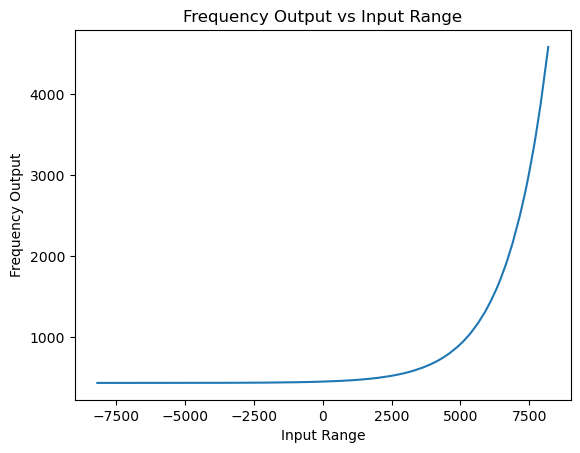

Frequency at input 0: 456.1822861433029


In [130]:
#print out input range
# create hex of input range
def hex_twos_complement(value, bit_width):
    if value < 0:
        value = (1 << bit_width) + value
    return hex(value)
input_hex = np.zeros(2**(BIT_WIDTH), dtype=object)
for i in range(len(input_range)):
    input_hex[i] = hex_twos_complement(input_range[i], BIT_WIDTH)
print("Beginning of input range:", input_range[:3], "Hex: ", input_hex[:3])
print("End of input range:", input_range[-3:], "Hex: ", input_hex[-3:])

#iterate through all elements in input range and calculate the respective frequency out (in stages)
freq_out = np.zeros(len(input_range))
for i in range(len(input_range)):
    #grab sign bit
    sign_bit = (input_range[i] >> (BIT_WIDTH-1)) & 1
    #grab int bits
    int_bits = (input_range[i] >> FRAC_BITS) & ((1 << INT_BITS) - 1)
    #grab frac bits
    frac_bits = input_range[i] & ((1 << FRAC_BITS) - 1)

    #print("Value:", input_range[i], "hex:", input_hex[i], "Sign bit:", sign_bit, "Int bits:", int_bits, "Frac bits:", frac_bits)

    # calculate the value akin to how we'll do it in HW
    # sign_bit = 1 if negative, 0 if positive

    if sign_bit:
        # int bits need to be treated as signed values
        # won't need to be as convoluted in hw since why tf am I simulating this in python
        value = (frac_lut_val[frac_bits]) >> (2**INT_BITS-int_bits)
    else:
        #index into the lut 
        value = (frac_lut_val[frac_bits]) << int_bits

    freq_out[i] = phase_inc_to_freq(value + BASE_PHASE_INC)

#plot
import matplotlib.pyplot as plt
plt.plot(input_range, freq_out)
plt.xlabel("Input Range")
plt.ylabel("Frequency Output")
plt.title("Frequency Output vs Input Range")
plt.show()

# why is the frequency at 0 not just passthrough? It should be A440
print("Frequency at input 0:", freq_out[len(input_range)//2])

In [111]:
5 >> 1

2